# 11. Temporal Trajectory Analysis for Transient Stability Assessment

This notebook demonstrates how to leverage the full temporal trajectory data from
time-domain simulations for improved transient stability assessment.

**Key capabilities:**
- Load raw event trajectory data (time series)
- Extract 100+ physics-informed temporal features
- Run early prediction experiments (accuracy vs. observation time)
- Create publication-quality visualizations

## Configuration

Change `N_EVENTS` to control how many events are loaded.
Start with a small number for testing, increase for publication results.

In [1]:
# Configuration - change these for your runs
N_EVENTS = 20          # Number of events to load (5 for testing, 10000 for full)
GRID = 'NewEngland'   # 'NewEngland' or 'NineBusSystem'
OUTPUT_DIR = '../papers/ieeaccess25/Images/temporal'
RANDOM_STATE = 42

In [2]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.tranpy.datasets.temporal_loaders import (
    load_temporal_dataset,
    get_generator_columns,
    get_bus_columns,
)
from src.tranpy.features.temporal import TemporalFeatureExtractor
from src.tranpy.features.early_prediction import (
    run_early_prediction_experiment,
    find_knee_point,
)
from src.tranpy.visualization.temporal import (
    set_ieee_style,
    plot_trajectory_comparison,
    plot_phase_portrait,
    plot_voltage_heatmap,
    plot_early_prediction_curve,
    plot_feature_importance_heatmap,
    plot_multi_generator_trajectories,
)

set_ieee_style()
%matplotlib inline

## 1. Load Event Trajectory Data

In [3]:
dataset = load_temporal_dataset(GRID, n_events=N_EVENTS)
print(dataset)
print(f'\nLabels: {dataset.labels}')
print(f'Stable: {sum(dataset.labels == 0)}, Unstable: {sum(dataset.labels == 1)}')

Loading 20 events from NewEngland (source=auto)...
Loaded 20 events: 10 stable, 10 unstable
TemporalDataset(grid='NewEngland', n_events=20, stable=10, unstable=10)

Labels: [0 0 0 1 1 0 0 1 1 0 1 1 1 0 1 1 0 1 0 0]
Stable: 10, Unstable: 10


In [4]:
# Inspect a single event
event = dataset.events[0]
print(event)
print(f'Duration: {event.duration:.2f}s')
print(f'Sampling rate: {event.sampling_rate:.1f} Hz')
print(f'\nGenerator columns:')
gen_cols = get_generator_columns(event.trajectory)
for gen_id, cols in gen_cols.items():
    print(f'  {gen_id}: {len(cols)} variables')

TemporalEventData(event=0, grid='NewEngland', timesteps=344, features=322, label=0)
Duration: 10.10s
Sampling rate: 34.1 Hz

Generator columns:
  G 01: 17 variables
  G 02: 17 variables
  G 03: 17 variables
  G 04: 17 variables
  G 05: 17 variables
  G 06: 17 variables
  G 07: 17 variables
  G 08: 17 variables
  G 09: 17 variables
  G 10: 17 variables


## 2. Trajectory Visualizations

### 2.1 Rotor Angle Trajectories (Stable vs Unstable)

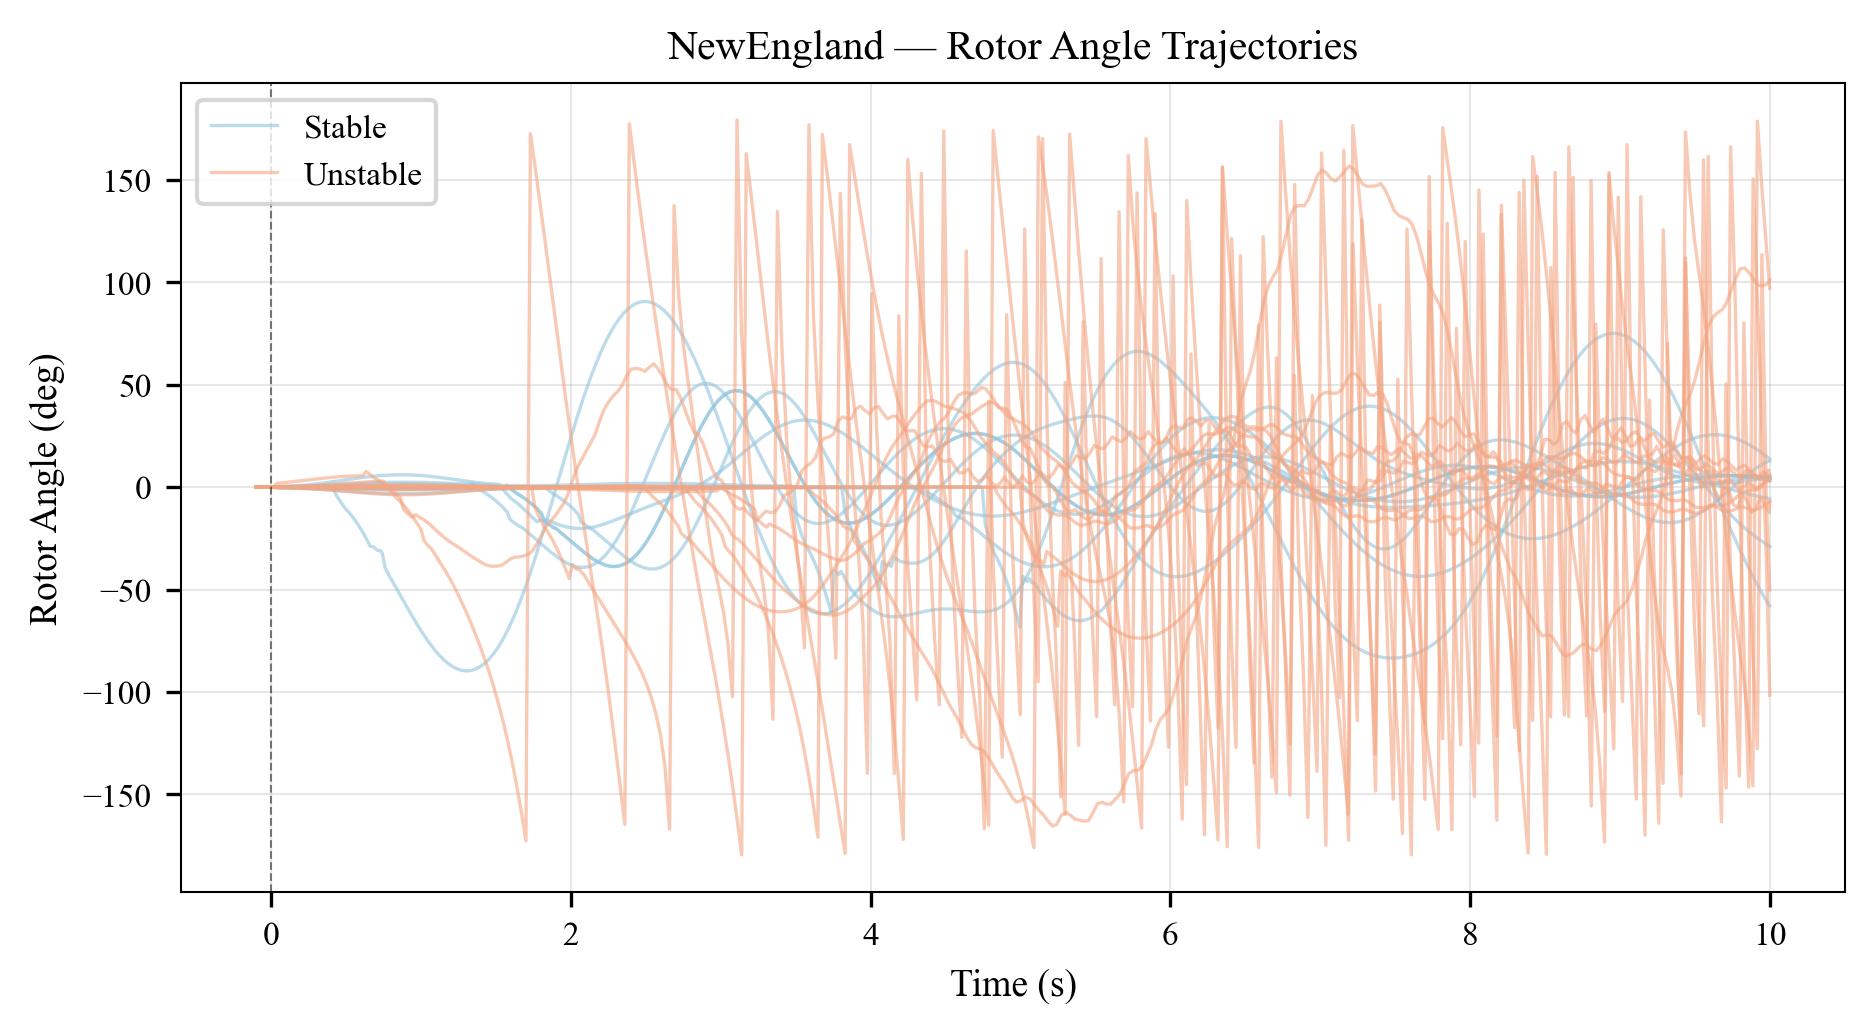

In [5]:
fig = plot_trajectory_comparison(
    dataset, variable='c:firot',
    title=f'{GRID} — Rotor Angle Trajectories',
    save_path=f'{OUTPUT_DIR}/{GRID.lower()}_rotor_angle_comparison.png',
)
plt.show()

### 2.2 Speed Deviation Trajectories

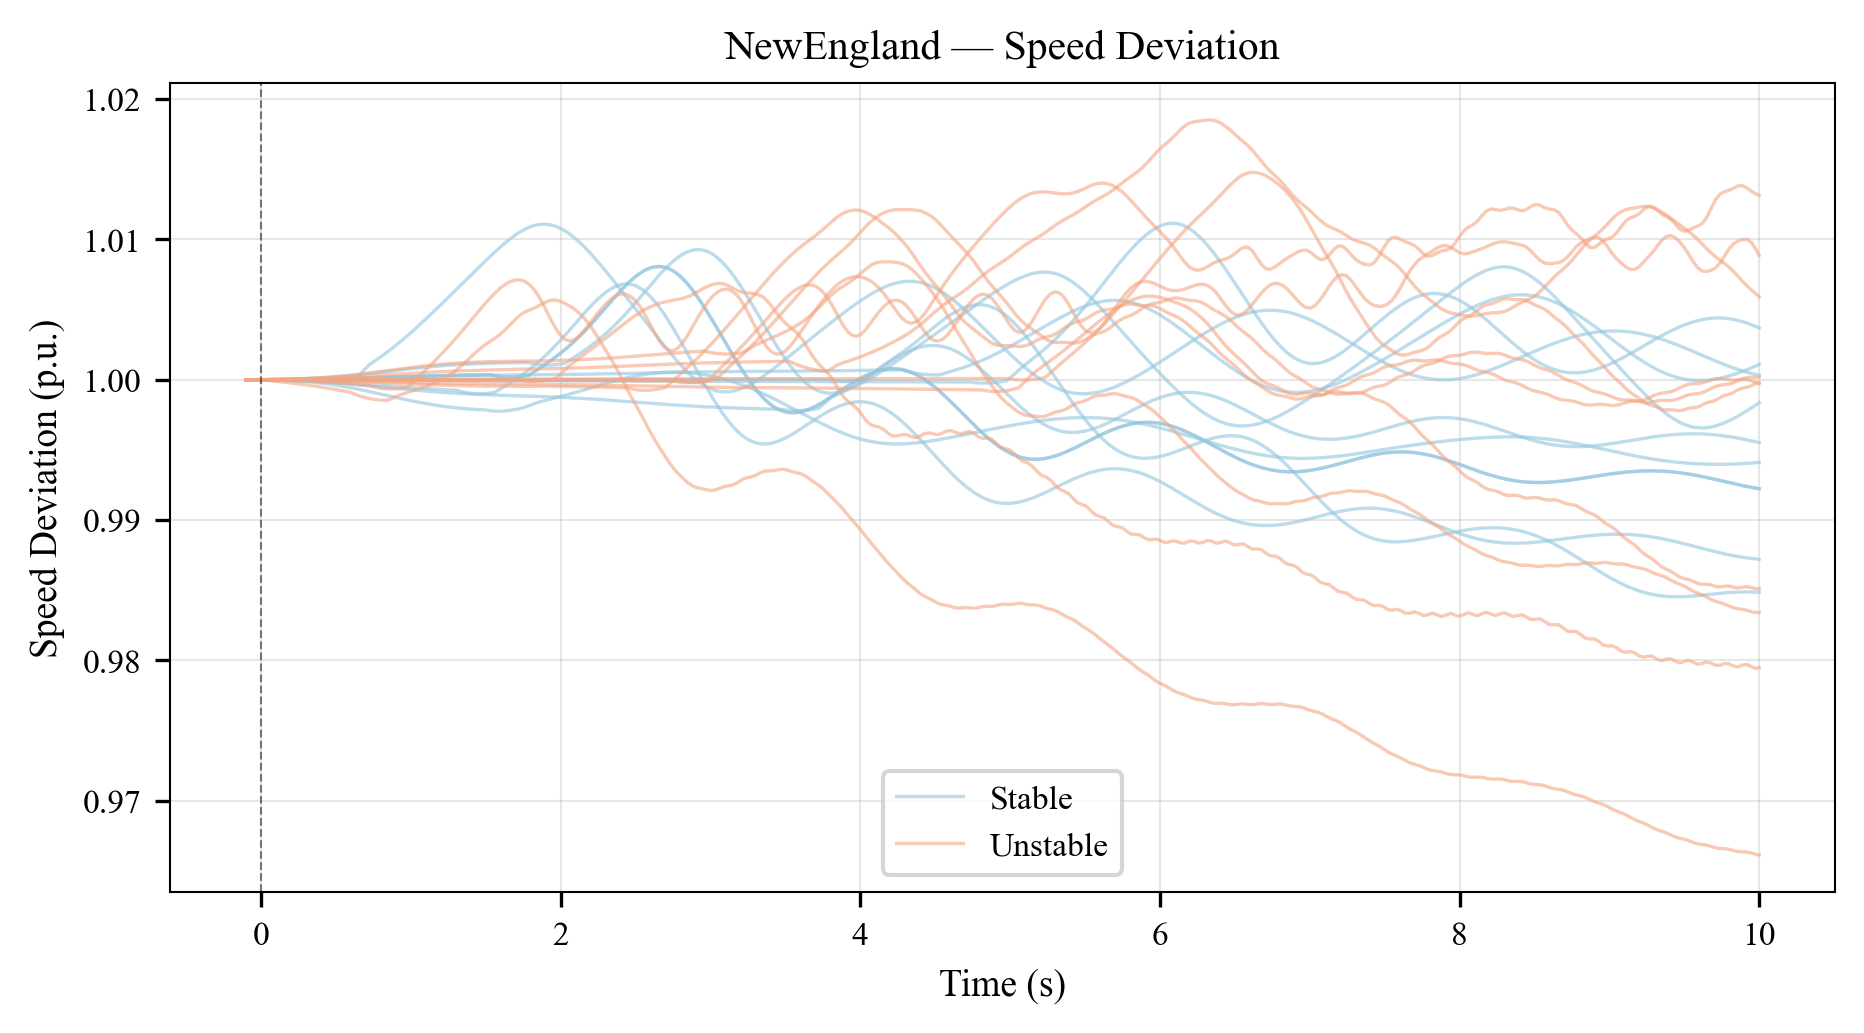

In [6]:
fig = plot_trajectory_comparison(
    dataset, variable='s:xspeed',
    title=f'{GRID} — Speed Deviation',
    save_path=f'{OUTPUT_DIR}/{GRID.lower()}_speed_comparison.png',
)
plt.show()

### 2.3 Phase Portraits (δ vs ω)

Phase portraits reveal the dynamical system behavior:
- **Stable:** Closed orbits converging to equilibrium
- **Unstable:** Diverging trajectories with loss of synchronism

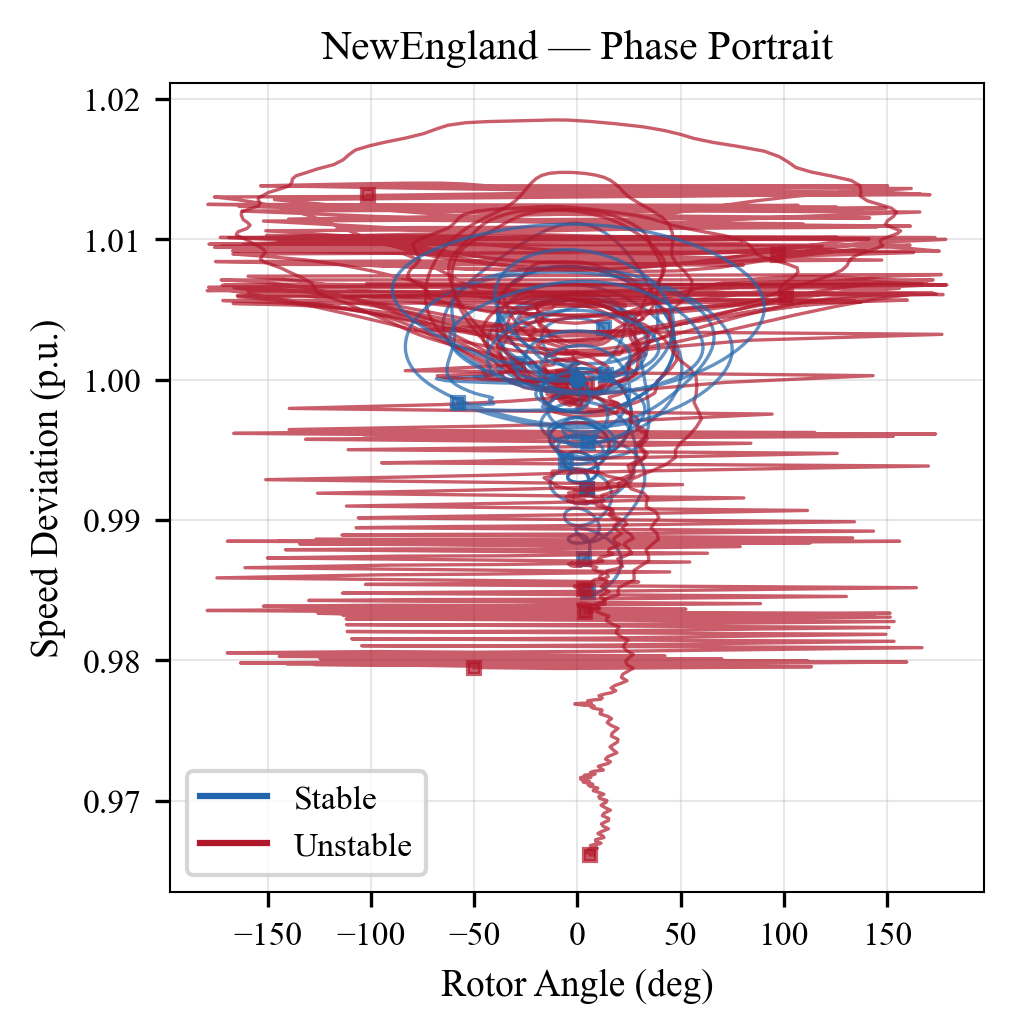

In [7]:
fig = plot_phase_portrait(
    dataset,
    title=f'{GRID} — Phase Portrait',
    save_path=f'{OUTPUT_DIR}/{GRID.lower()}_phase_portrait.png',
)
plt.show()

### 2.4 Voltage Evolution Heatmaps

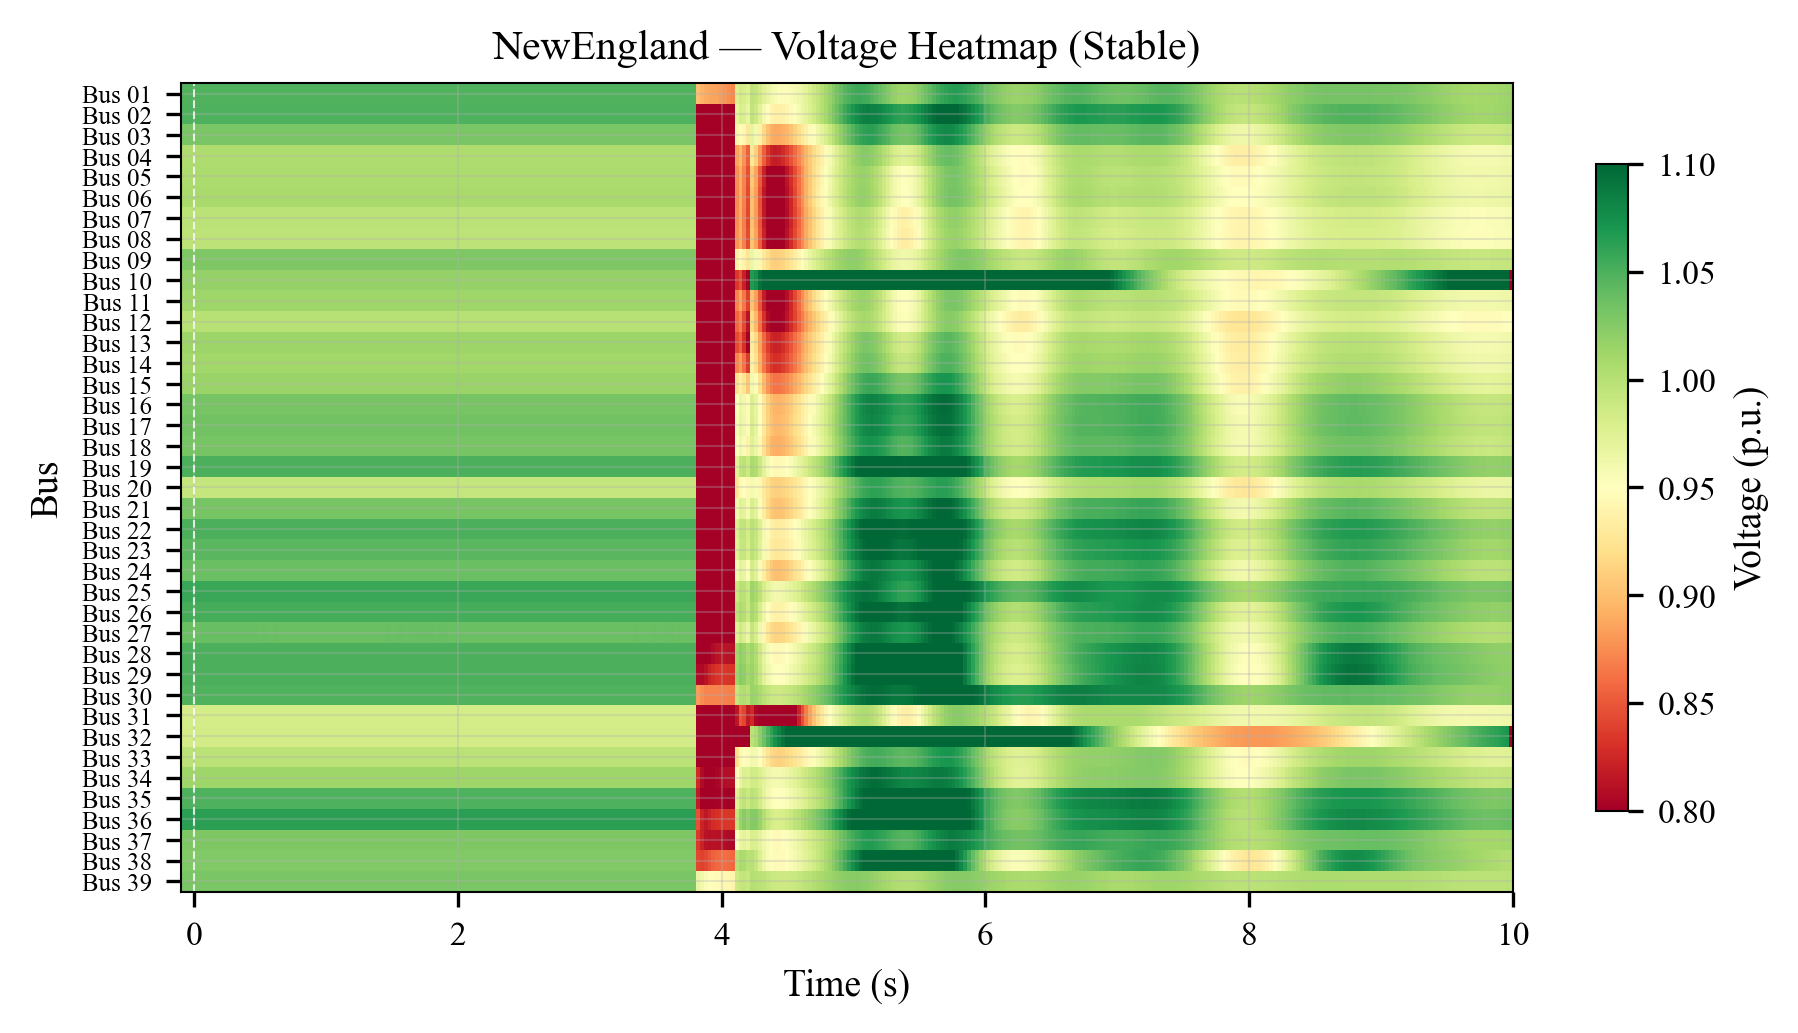

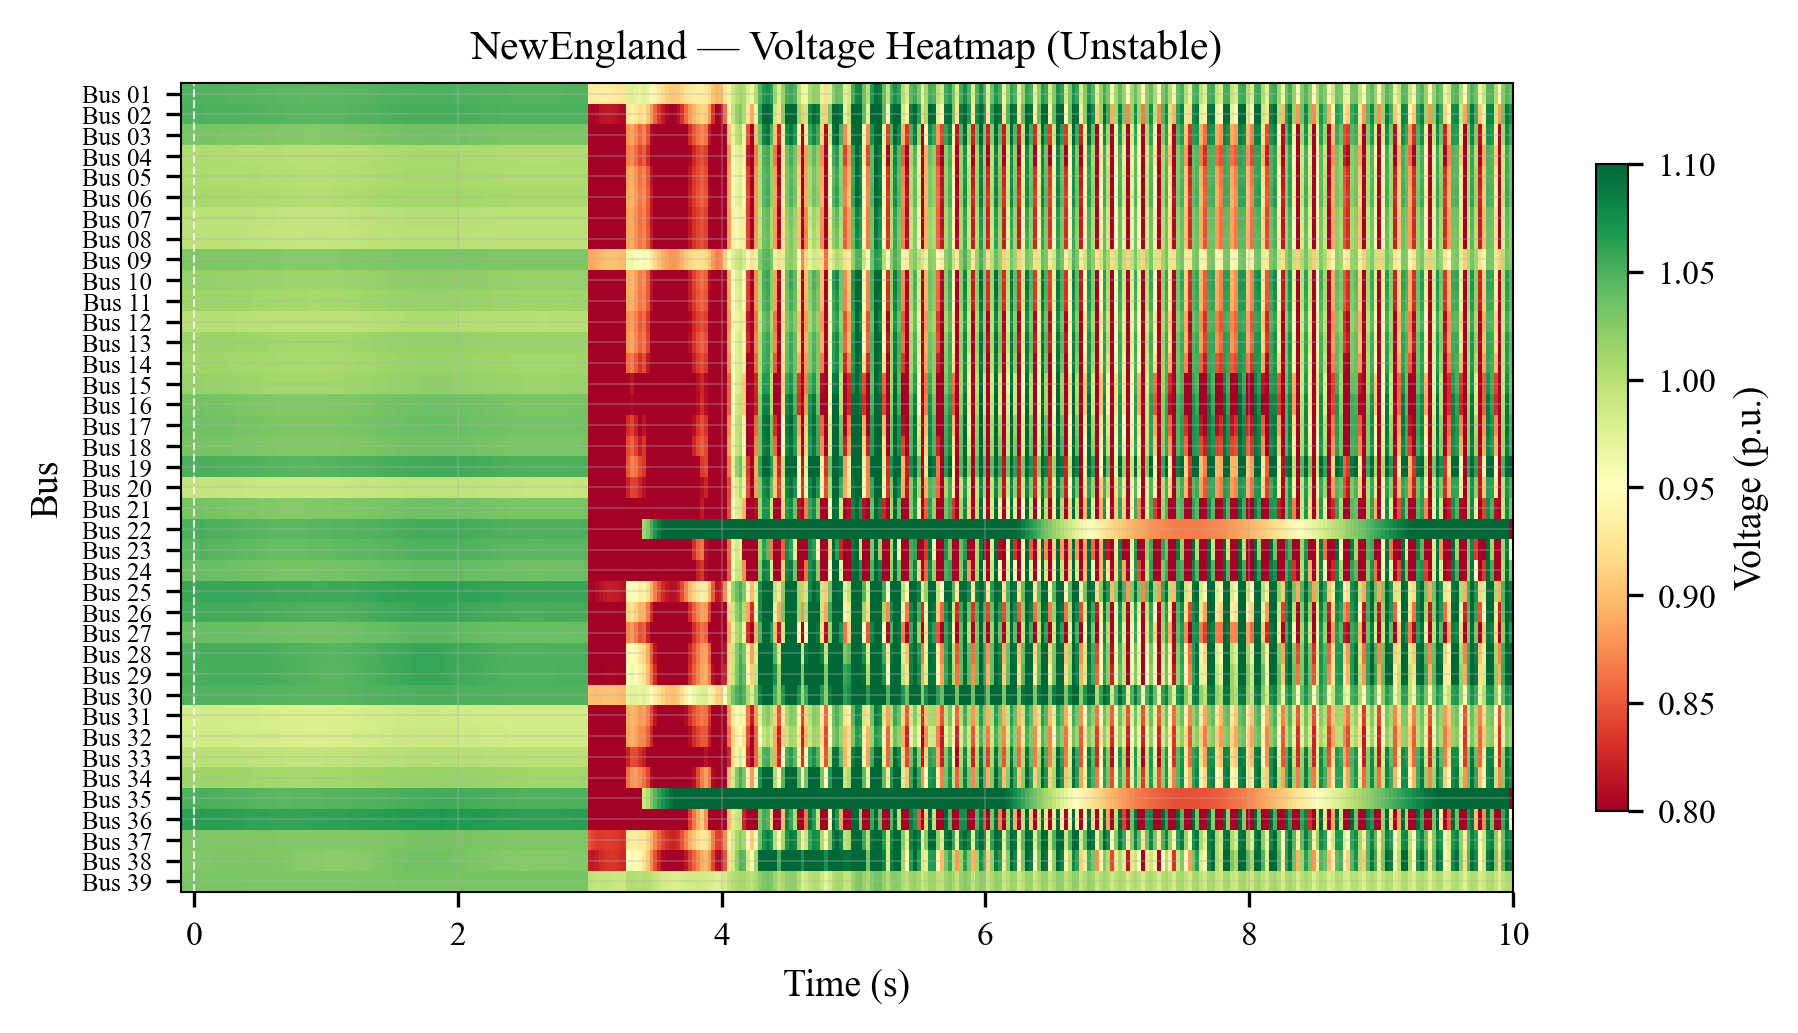

In [8]:
stable_events = dataset.get_stable_events()
unstable_events = dataset.get_unstable_events()

if stable_events:
    fig = plot_voltage_heatmap(
        stable_events[0],
        title=f'{GRID} — Voltage Heatmap (Stable)',
        save_path=f'{OUTPUT_DIR}/{GRID.lower()}_voltage_heatmap_stable.png',
    )
    plt.show()

if unstable_events:
    fig = plot_voltage_heatmap(
        unstable_events[0],
        title=f'{GRID} — Voltage Heatmap (Unstable)',
        save_path=f'{OUTPUT_DIR}/{GRID.lower()}_voltage_heatmap_unstable.png',
    )
    plt.show()

### 2.5 Multi-Generator Rotor Angle Plots

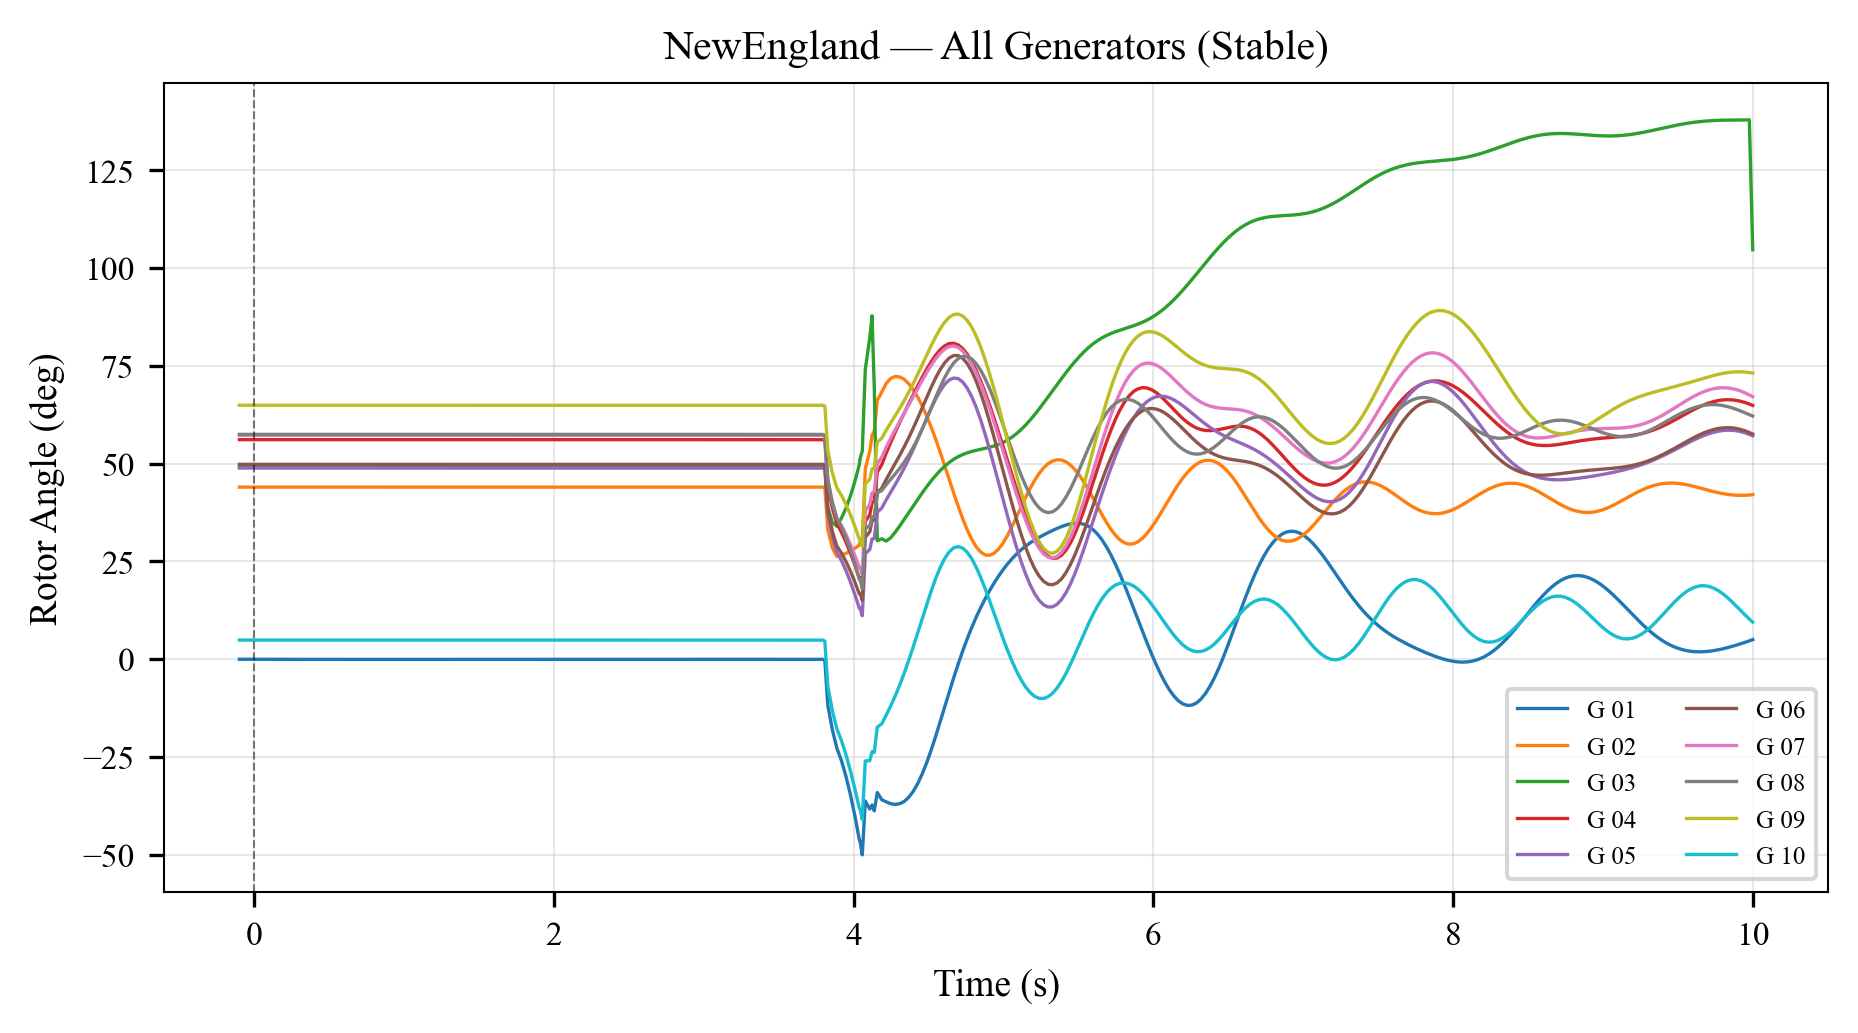

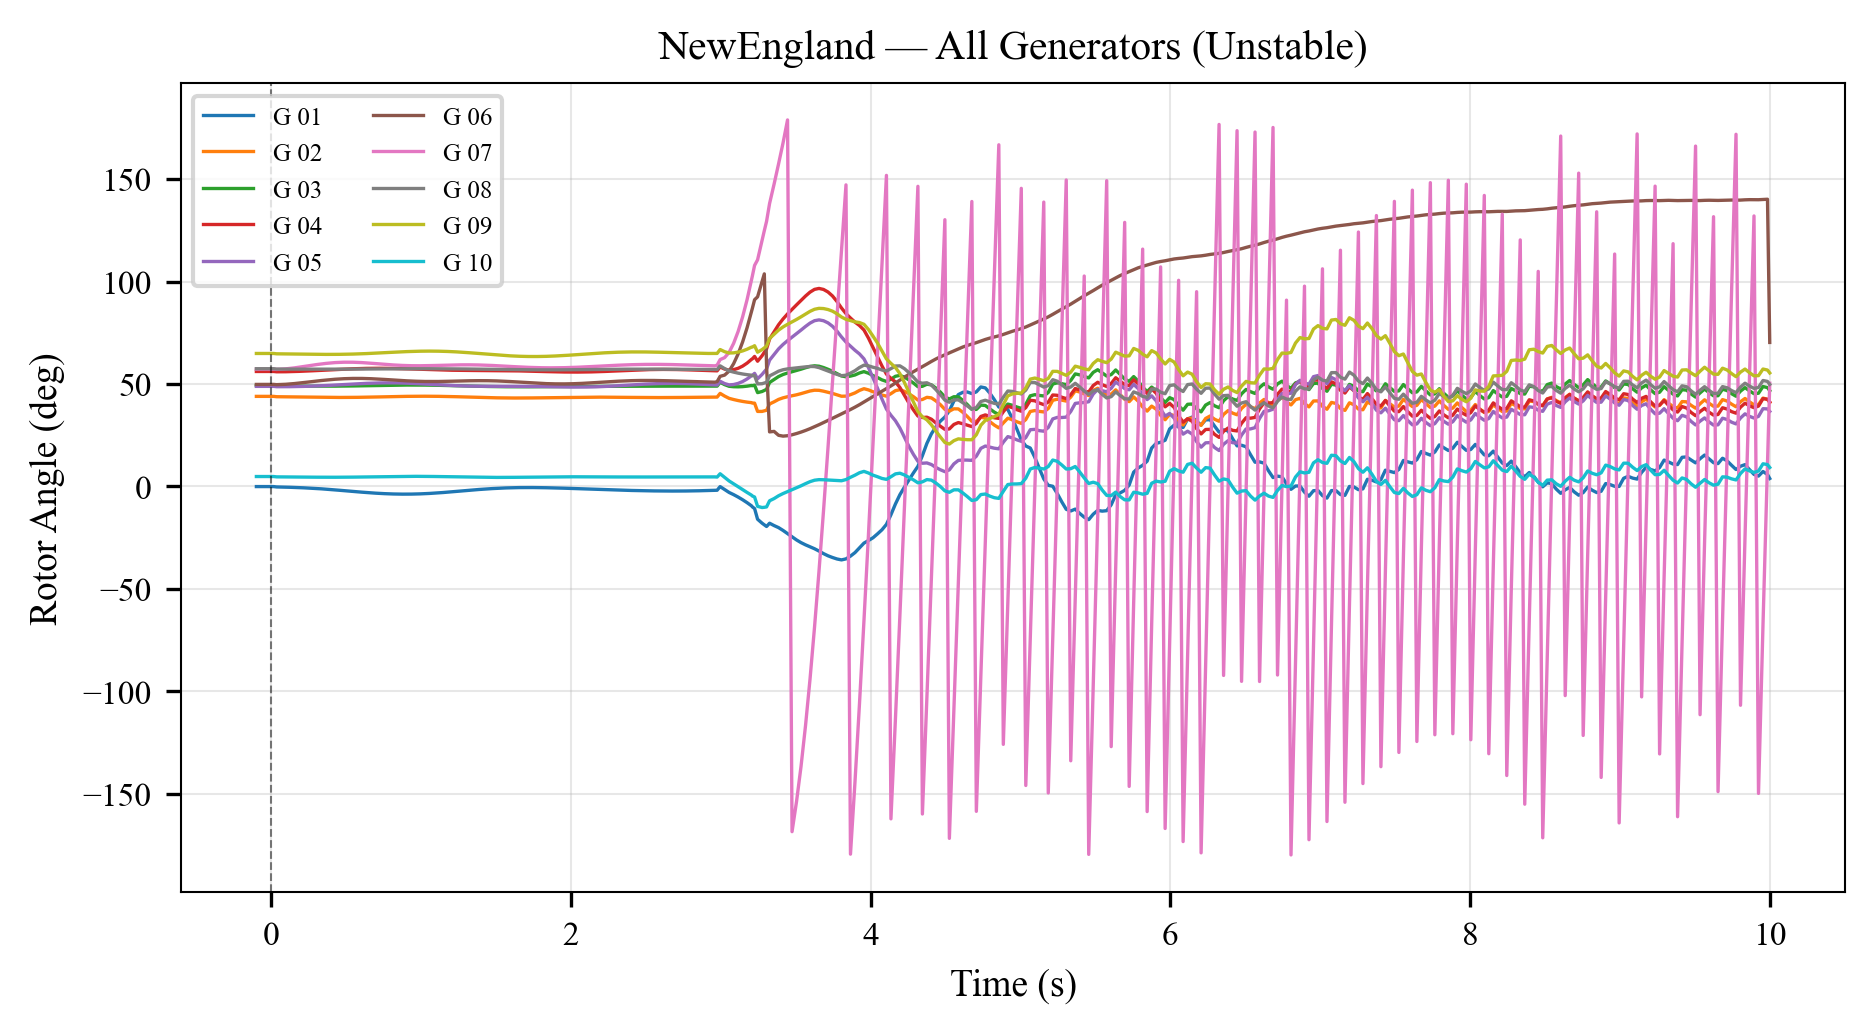

In [9]:
if stable_events:
    fig = plot_multi_generator_trajectories(
        stable_events[0], variable='c:firot',
        title=f'{GRID} — All Generators (Stable)',
        save_path=f'{OUTPUT_DIR}/{GRID.lower()}_all_gen_stable.png',
    )
    plt.show()

if unstable_events:
    fig = plot_multi_generator_trajectories(
        unstable_events[0], variable='c:firot',
        title=f'{GRID} — All Generators (Unstable)',
        save_path=f'{OUTPUT_DIR}/{GRID.lower()}_all_gen_unstable.png',
    )
    plt.show()

## 3. Temporal Feature Extraction

Extract physics-informed features from the full trajectory.

In [10]:
# Full window extraction
extractor = TemporalFeatureExtractor()
X, feature_names = extractor.transform(dataset)

print(f'Feature matrix shape: {X.shape}')
print(f'Number of features: {len(feature_names)}')
print(f'\nFeature categories:')

# Count features by category
categories = {'rotor': 0, 'voltage': 0, 'frequency': 0, 'power': 0, 'coherency': 0}
for name in feature_names:
    if any(k in name for k in ['delta', 'damping', 'swing', 'speed', 'freq_dev']):
        categories['rotor'] += 1
    elif 'voltage' in name:
        categories['voltage'] += 1
    elif any(k in name for k in ['freq', 'rocof']):
        categories['frequency'] += 1
    elif any(k in name for k in ['power', 'reactive']):
        categories['power'] += 1
    elif any(k in name for k in ['angle_spread', 'divergence', 'relative', 'coi', 'angle_std']):
        categories['coherency'] += 1

for cat, count in categories.items():
    print(f'  {cat}: {count} features')

Feature matrix shape: (20, 165)
Number of features: 165

Feature categories:
  rotor: 122 features
  voltage: 6 features
  frequency: 7 features
  power: 21 features
  coherency: 9 features


In [11]:
# Compare stable vs unstable feature distributions
labels = dataset.labels
stable_mask = labels == 0
unstable_mask = labels == 1

# Compute discriminative power (relative difference)
diffs = []
for i, name in enumerate(feature_names):
    s_mean = np.mean(X[stable_mask, i]) if np.any(stable_mask) else 0
    u_mean = np.mean(X[unstable_mask, i]) if np.any(unstable_mask) else 0
    rel_diff = abs(u_mean - s_mean) / (abs(s_mean) + 1e-10)
    diffs.append((name, s_mean, u_mean, rel_diff))

diffs.sort(key=lambda x: -x[3])

print('Top 20 most discriminative temporal features:')
print(f'{"Feature":<40} {"Stable":>12} {"Unstable":>12} {"Rel.Diff":>10}')
print('-' * 76)
for name, s, u, d in diffs[:20]:
    print(f'{name:<40} {s:>12.4f} {u:>12.4f} {d:>10.2f}')

Top 20 most discriminative temporal features:
Feature                                        Stable     Unstable   Rel.Diff
----------------------------------------------------------------------------
G07_delta_rate_mean                           25.2865     982.2737      37.85
G08_delta_final                                1.6038     -56.7491      36.38
G09_delta_rate_mean                           29.9456    1072.4108      34.81
G08_delta_rate_mean                           18.0824     621.3143      33.36
sys_angle_divergence_rate_mean                46.6954    1078.6302      22.10
G09_delta_rate_max                           399.6154    8358.1944      19.92
G10_delta_rate_mean                           22.9832     469.9195      19.45
G09_speed_dev_final                           -0.0031       0.0558      19.00
G03_delta_rate_mean                           14.1296     266.1099      17.83
G06_speed_dev_final                           -0.0037       0.0600      17.27
sys_rocof_mean     

## 4. Early Prediction Experiment

Evaluate how prediction accuracy changes with observation time window.
This determines the minimum time needed for reliable stability prediction.

In [12]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

classifiers = {
    'ETrees': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'RF': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'GB': GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'DT': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'LR': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'SVM-R': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
}

time_windows = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]

results = run_early_prediction_experiment(
    dataset, classifiers,
    time_windows=time_windows,
    n_splits=min(3, sum(labels == 0), sum(labels == 1)),
    random_state=RANDOM_STATE,
    verbose=True
)

Time window: 0.10s
  ETrees: Acc=0.6667, AUC=0.6944
  RF: Acc=0.6111, AUC=0.5185
  GB: Acc=0.5079, AUC=0.5370
  DT: Acc=0.5556, AUC=0.5694
  LR: Acc=0.5000, AUC=0.4630
  SVM-R: Acc=0.3095, AUC=0.5185
Time window: 0.25s
  ETrees: Acc=0.6111, AUC=0.5926
  RF: Acc=0.6111, AUC=0.5278
  GB: Acc=0.5556, AUC=0.6111
  DT: Acc=0.5556, AUC=0.5694
  LR: Acc=0.4048, AUC=0.3519
  SVM-R: Acc=0.3571, AUC=0.2083
Time window: 0.50s
  ETrees: Acc=0.5079, AUC=0.4861
  RF: Acc=0.6032, AUC=0.5185
  GB: Acc=0.5000, AUC=0.4583
  DT: Acc=0.4524, AUC=0.4722
  LR: Acc=0.4048, AUC=0.3519
  SVM-R: Acc=0.5079, AUC=0.5093
Time window: 1.00s
  ETrees: Acc=0.5556, AUC=0.5278
  RF: Acc=0.5556, AUC=0.5787
  GB: Acc=0.5159, AUC=0.5417
  DT: Acc=0.5159, AUC=0.5139
  LR: Acc=0.6111, AUC=0.4630
  SVM-R: Acc=0.3571, AUC=0.7037
Time window: 2.00s
  ETrees: Acc=0.6032, AUC=0.6667
  RF: Acc=0.4444, AUC=0.5880
  GB: Acc=0.5476, AUC=0.4954
  DT: Acc=0.5476, AUC=0.5139
  LR: Acc=0.6032, AUC=0.5463
  SVM-R: Acc=0.6508, AUC=0.4074


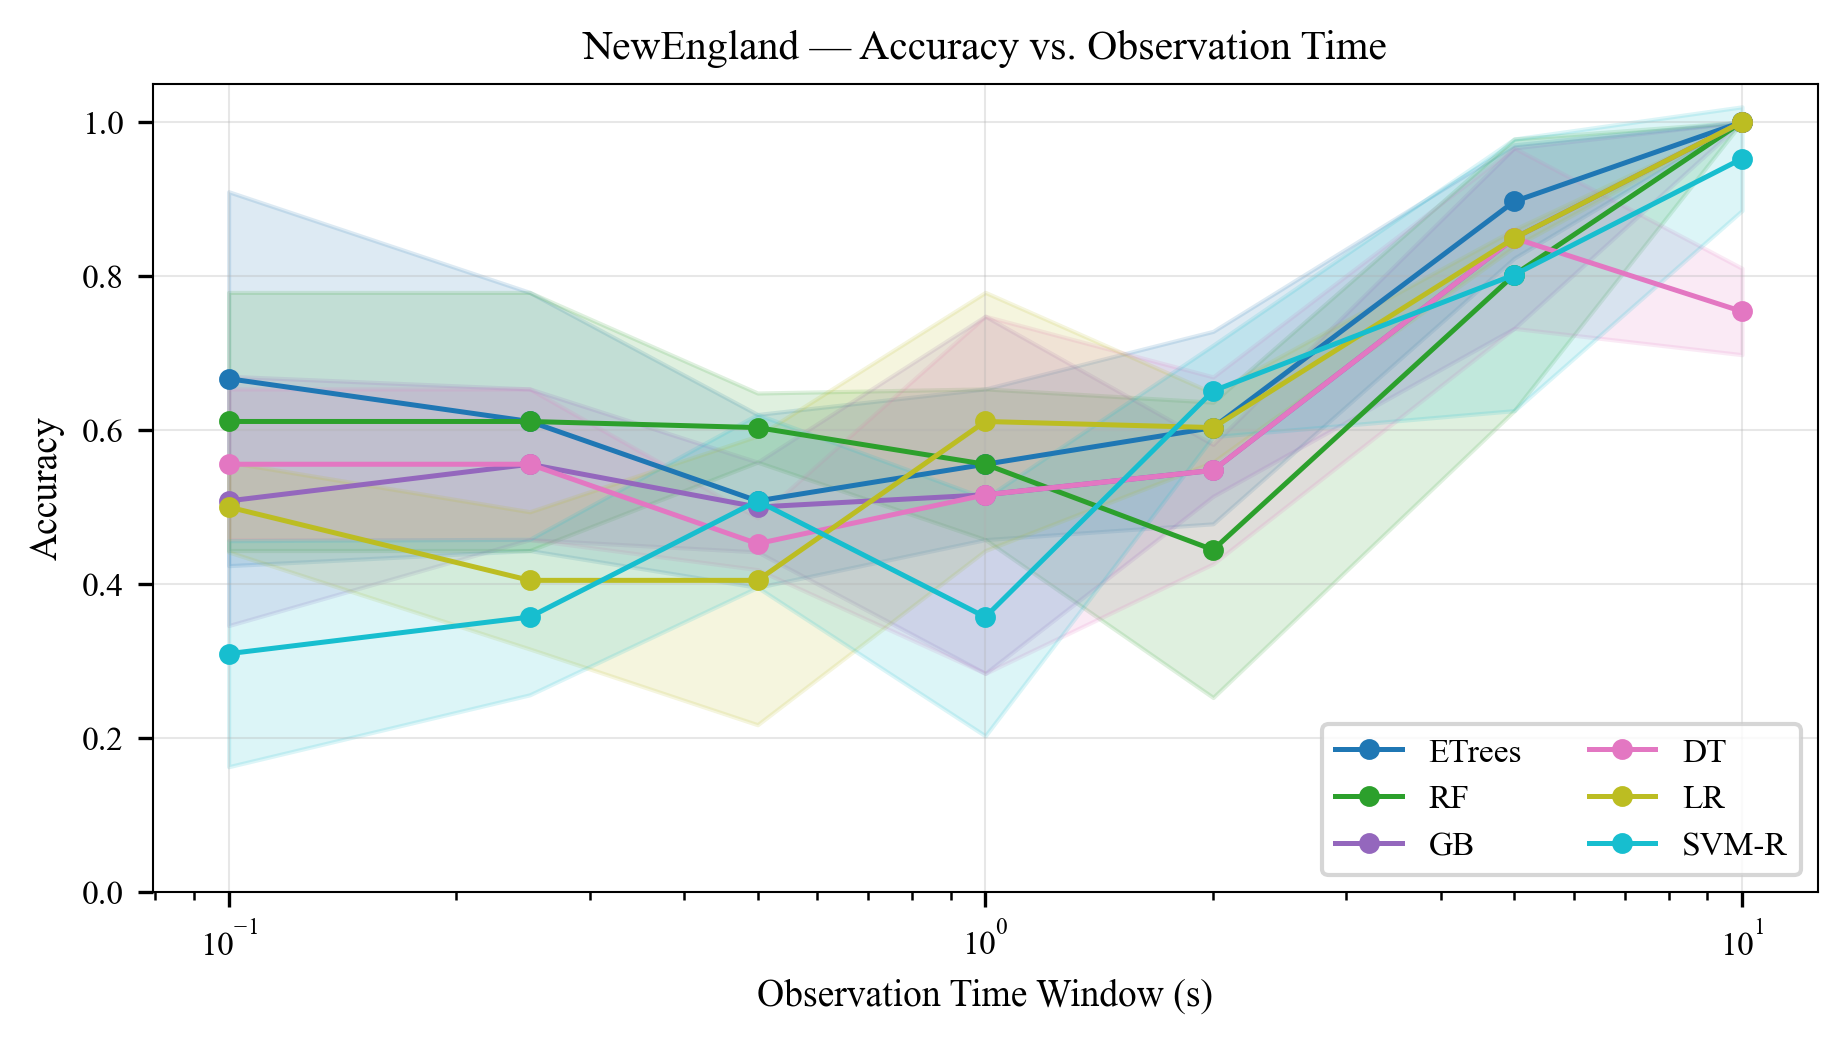

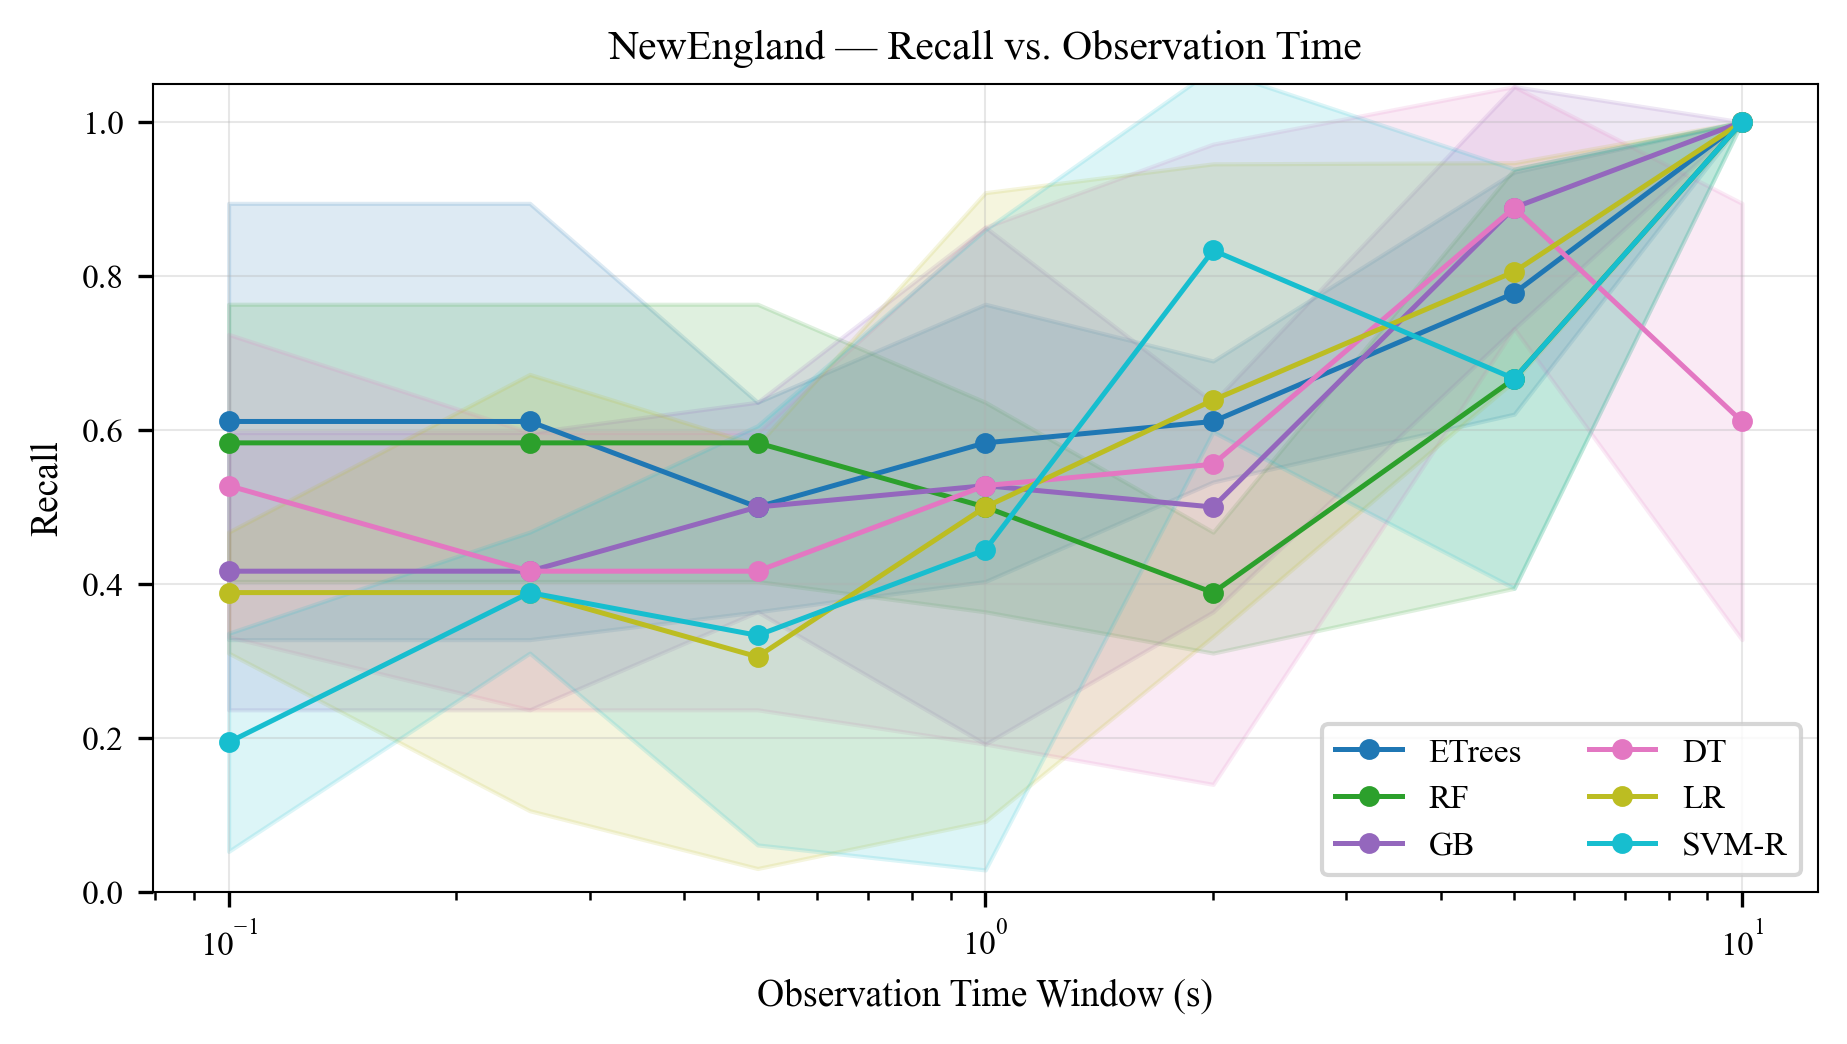

In [13]:
# Plot early prediction curves
fig = plot_early_prediction_curve(
    results, metric='accuracy',
    title=f'{GRID} — Accuracy vs. Observation Time',
    save_path=f'{OUTPUT_DIR}/{GRID.lower()}_early_prediction_accuracy.png',
)
plt.show()

fig = plot_early_prediction_curve(
    results, metric='recall',
    title=f'{GRID} — Recall vs. Observation Time',
    save_path=f'{OUTPUT_DIR}/{GRID.lower()}_early_prediction_recall.png',
)
plt.show()

In [14]:
# Summary table
summary = results.pivot_table(
    index='model', columns='time_window',
    values='accuracy', aggfunc='first'
)
print('Accuracy by Model and Time Window:')
print(summary.round(4).to_string())

Accuracy by Model and Time Window:
time_window   0.10    0.25    0.50    1.00    2.00    5.00    10.00
model                                                              
DT           0.5556  0.5556  0.4524  0.5159  0.5476  0.8492  0.7540
ETrees       0.6667  0.6111  0.5079  0.5556  0.6032  0.8968  1.0000
GB           0.5079  0.5556  0.5000  0.5159  0.5476  0.8492  1.0000
LR           0.5000  0.4048  0.4048  0.6111  0.6032  0.8492  1.0000
RF           0.6111  0.6111  0.6032  0.5556  0.4444  0.8016  1.0000
SVM-R        0.3095  0.3571  0.5079  0.3571  0.6508  0.8016  0.9524


## 5. Feature Importance Analysis

Analyze which features are most important at different time windows.

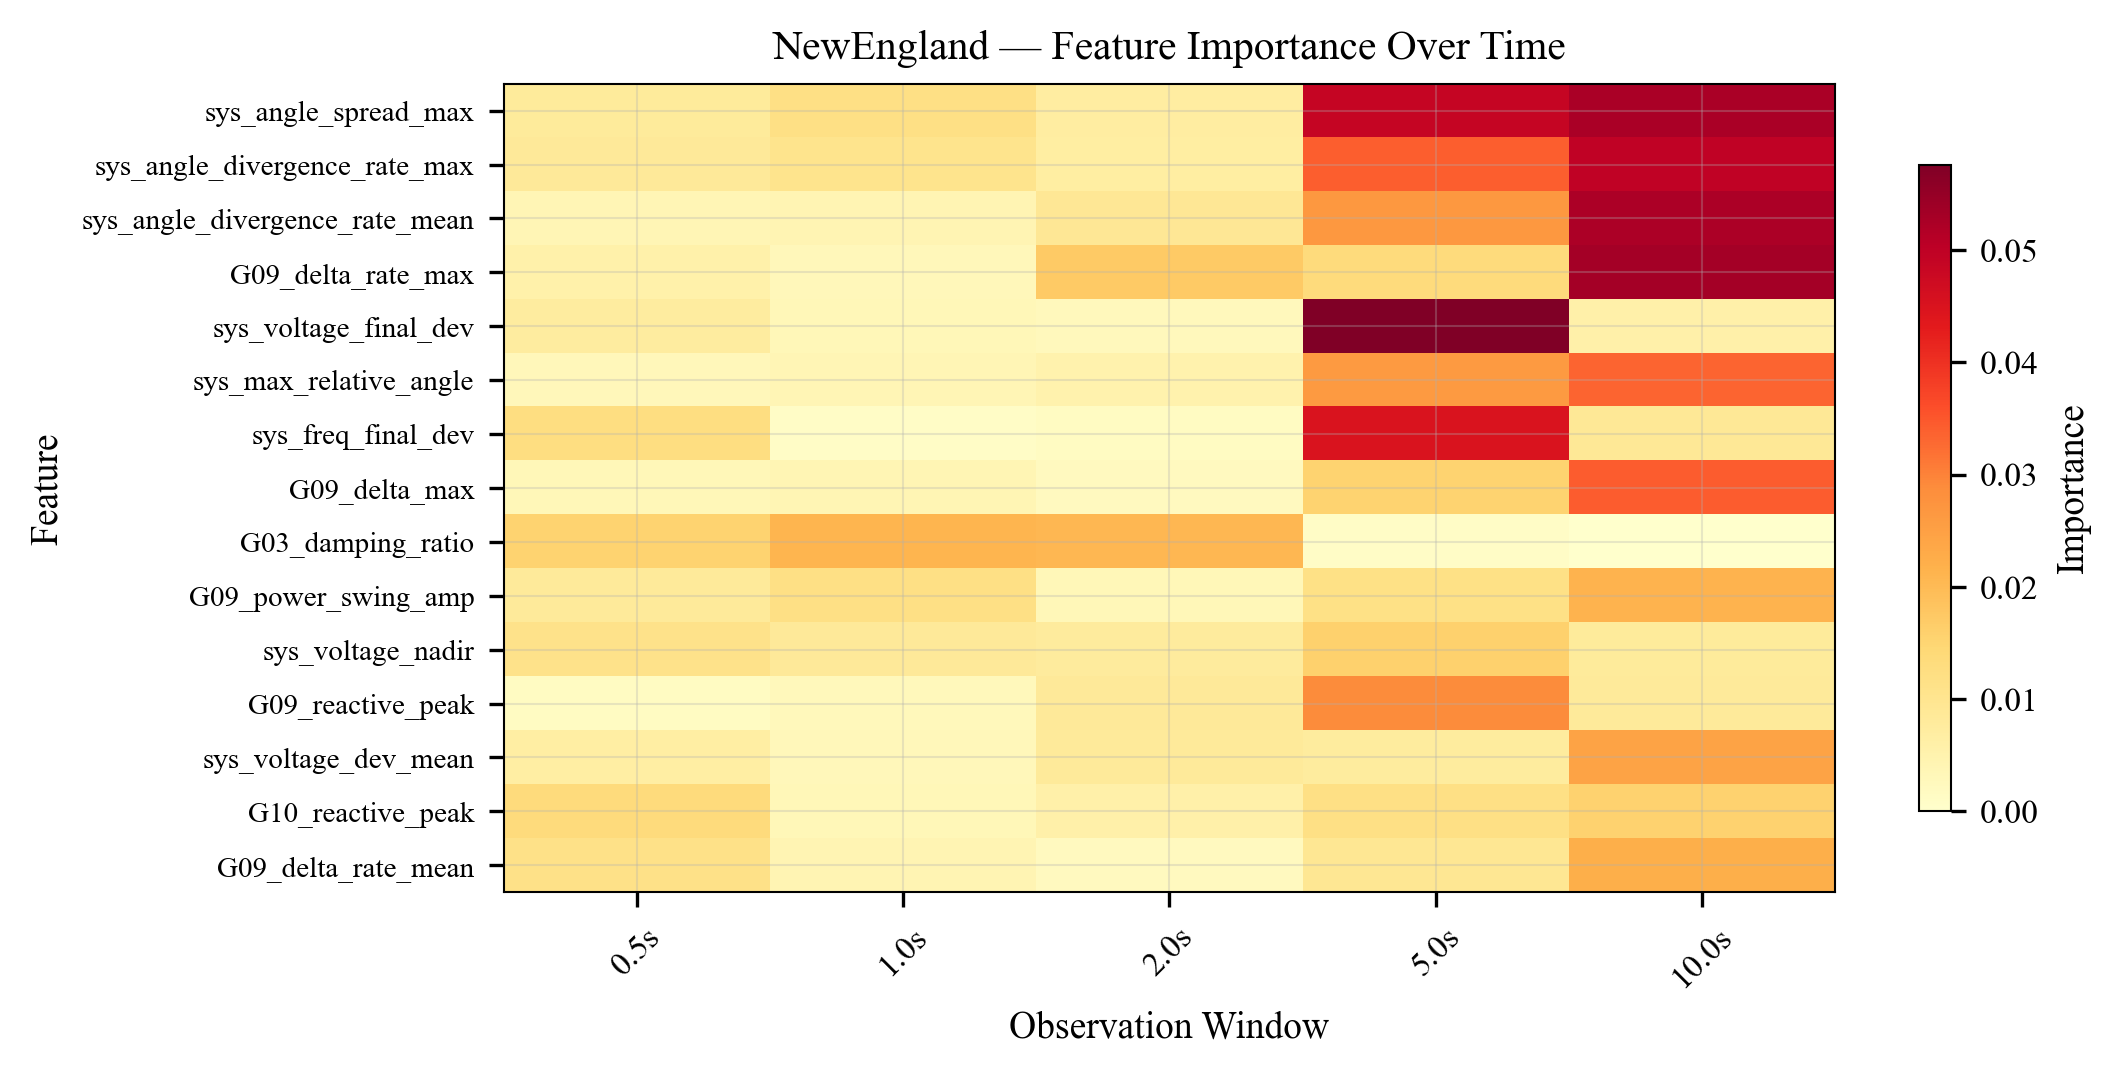

In [15]:
from sklearn.preprocessing import StandardScaler

importance_by_window = {}

for tw in [0.5, 1.0, 2.0, 5.0, 10.0]:
    ext = TemporalFeatureExtractor(time_window=tw)
    X_tw, names_tw = ext.transform(dataset)
    X_tw = np.nan_to_num(X_tw, nan=0.0, posinf=0.0, neginf=0.0)
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_tw)
    
    clf = ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE)
    clf.fit(X_scaled, labels)
    
    importance_by_window[tw] = pd.Series(
        clf.feature_importances_, index=names_tw
    )

fig = plot_feature_importance_heatmap(
    importance_by_window, top_n=15,
    title=f'{GRID} — Feature Importance Over Time',
    save_path=f'{OUTPUT_DIR}/{GRID.lower()}_feature_importance_heatmap.png',
)
plt.show()

## 6. Summary Statistics

In [16]:
print(f'=== {GRID} Temporal Analysis Summary ===')
print(f'Events loaded: {len(dataset.events)}')
print(f'Stable: {sum(labels == 0)}, Unstable: {sum(labels == 1)}')
print(f'Temporal features extracted: {len(feature_names)}')
print(f'Time windows tested: {time_windows}')
print(f'\nTop 5 discriminative features:')
for name, s, u, d in diffs[:5]:
    print(f'  {name}: rel_diff={d:.2f}')

# Find best model and knee point
best = results.loc[results.groupby('model')['accuracy'].idxmax()]
print(f'\nBest accuracy per model (best time window):')
for _, row in best.iterrows():
    print(f'  {row["model"]}: {row["accuracy"]:.4f} at {row["time_window"]}s')

=== NewEngland Temporal Analysis Summary ===
Events loaded: 20
Stable: 10, Unstable: 10
Temporal features extracted: 165
Time windows tested: [0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]

Top 5 discriminative features:
  G07_delta_rate_mean: rel_diff=37.85
  G08_delta_final: rel_diff=36.38
  G09_delta_rate_mean: rel_diff=34.81
  G08_delta_rate_mean: rel_diff=33.36
  sys_angle_divergence_rate_mean: rel_diff=22.10

Best accuracy per model (best time window):
  DT: 0.8492 at 5.0s
  ETrees: 1.0000 at 10.0s
  GB: 1.0000 at 10.0s
  LR: 1.0000 at 10.0s
  RF: 1.0000 at 10.0s
  SVM-R: 0.9524 at 10.0s
